# Đánh giá RAG — tri thức địa danh Huế

Notebook chạy toàn bộ benchmark RAG và in số liệu để kiểm tra:

1. **Kho dữ liệu**: số bài, số chunk, phân bố độ dài.
2. **Dựng chỉ mục**: thời gian embed, chunk/giây, VRAM đỉnh cho từng embedder.
3. **Chất lượng truy hồi**: Hit@k, MRR@10, nDCG@5, P@5, Precision/Recall/F1@5 mức địa danh, AnswerHit@5, kèm CI 95% (bootstrap theo câu hỏi).
4. **Độ trễ truy hồi**: p50/p95.
5. **So sánh cặp** có CI: khác biệt có ý nghĩa khi CI không chứa 0.
6. **Phân tích lỗi**: câu truy hồi sai.
7. **Sinh câu trả lời**: TTFT (LLM và đầu-cuối), tổng thời gian, tokens/giây, độ phủ từ khoá đáp án, tỷ lệ trích dẫn, tỷ lệ từ chối.

Model đã chốt (17/10/2026): embedding `bge-m3`, `multilingual-e5-base`, `multilingual-e5-large`; LLM `qwen3.5:4b`, `qwen3.5:9b` qua Ollama; không reranker.
Cấu hình hệ thống chốt 18/10/2026: **hybrid bge-m3 + BM25**, LLM **qwen3.5:4b** (`rag/__init__.py`).

Chỉ chấm câu đã duyệt (`reviewed: true`, duyệt bằng `scripts/review_rag_queries.py`); đổi `REVIEWED_ONLY` để chấm tất cả.

**Định nghĩa nhanh**
- *Chunk liên quan*: chunk thuộc địa danh đúng của câu hỏi.
- *Hit@k*: có ít nhất một chunk liên quan trong top-k. *MRR@10*: 1/hạng của chunk liên quan đầu tiên.
- *nDCG@5*: chất lượng thứ tự top-5, chuẩn hoá về [0, 1].
- *Precision/Recall/F1@5 (mức địa danh)*: tập địa danh trong top-5 so với tập địa danh đúng; quan trọng với câu `multi`.
- *AnswerHit@5*: có chunk liên quan chứa đủ từ khoá đáp án (chỉ câu có `answer_keywords`).
- *TTFT*: thời gian tới ký tự trả lời đầu tiên. *TTFT đầu-cuối* = truy hồi + TTFT của LLM.


In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "rag").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rag import benchmark as bm, DEFAULT_EMBEDDER, DEFAULT_LLM
from rag.corpus import load_chunks, corpus_hash
from rag.dense import EMBEDDERS, EMB_DIR
from rag.metrics import bootstrap_ci

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

# ---- Cấu hình ----
EMBEDDER_KEYS = ["bge-m3", "e5-base", "e5-large"]
LLM_MODELS = [DEFAULT_LLM, "qwen3.5:9b"]   # model hệ thống + model so sánh
REVIEWED_ONLY = True      # chỉ chấm câu đã kiểm duyệt
GEN_RETRIEVER = f"hybrid_{DEFAULT_EMBEDDER}+bm25_multi"   # retriever đã chốt
GEN_EMBED_DEVICE = "cpu"  # khi sinh: đưa embedder về CPU để LLM có trọn VRAM (so sánh 4B/9B công bằng)
FORCE_REBUILD = True      # True: xoá cache embedding để đo lại thời gian dựng chỉ mục
RUN_GENERATION = True     # cần Ollama đang chạy
OUT = bm._out_dir()
print("Kết quả ghi vào", OUT)

Kết quả ghi vào C:\Users\baoba\OneDrive\Máy tính\Travel\data\qa\rag\2026-10-18


## 1. Kho dữ liệu

929 chunk, 74 bài, 73 bài gắn place_key


,count,mean,std,min,25%,50%,75%,max
độ dài chunk (ký tự),929.000,785.017,290.133,45.000,555.000,828.000,1038.000,1362.000


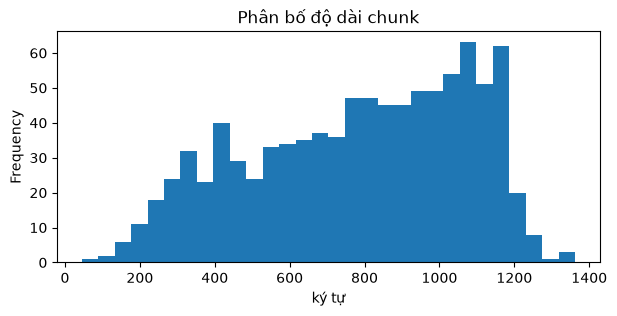

In [2]:
chunks = load_chunks()
lengths = pd.Series([len(c.text) for c in chunks])
pages = {c.title for c in chunks}
print(f"{len(chunks)} chunk, {len(pages)} bài, {len({c.title for c in chunks if c.place_key})} bài gắn place_key")
display(lengths.describe().to_frame("độ dài chunk (ký tự)").T)
ax = lengths.plot.hist(bins=30, figsize=(7, 3), title="Phân bố độ dài chunk")
ax.set_xlabel("ký tự"); plt.show()

### Bộ câu hỏi và kết quả kiểm duyệt

In [3]:
import json, yaml
all_queries = bm.load_queries()
reviews = {}
log = ROOT / "eval" / "rag_query_reviews.jsonl"
if log.exists():
    for line in log.read_text(encoding="utf-8").splitlines():
        if line.strip():
            r = json.loads(line); reviews[r["id"]] = r
raw = {q["id"]: q for q in yaml.safe_load((ROOT / "eval" / "rag_queries.yml").read_text(encoding="utf-8"))}
qdf = pd.DataFrame([{"id": q.id, "type": q.type, "author": raw[q.id].get("author", "claude (bản đầu)"),
                     "label": reviews.get(q.id, {}).get("label", "chưa duyệt"), "has_keywords": bool(q.answer_keywords)}
                    for q in all_queries])
display(pd.crosstab(qdf["type"], qdf["label"], margins=True, margins_name="tổng"))
bad = [(i, raw[i]["query"], reviews[i].get("note", "")) for i in qdf[qdf.label == "F"]["id"]]
if bad:
    print("Câu bị đánh sai (F), loại khỏi benchmark:")
    display(pd.DataFrame(bad, columns=["id", "query", "ghi chú"]))
queries = bm.load_queries(reviewed_only=REVIEWED_ONLY)
print(f"Chấm {len(queries)}/{len(all_queries)} câu. Câu có từ khoá đáp án: {sum(bool(q.answer_keywords) for q in queries)}.")
print("Lưu ý: bộ câu hỏi do AI soạn nháp, người duyệt T/F; chưa có câu hỏi thật từ người dùng.")

label,F,T,tổng
type,,,
descriptive,0,8,8
fact,0,121,121
multi,0,13,13
no_diacritics,0,19,19
paraphrase,1,27,28
tổng,1,188,189


Câu bị đánh sai (F), loại khỏi benchmark:


,id,query,ghi chú
0,q003,Ngôi chùa cổ có tháp bảy tầng nằm trên đồi bên bờ sông Hương,không có thông tin tháp bảy tầng


Chấm 188/189 câu. Câu có từ khoá đáp án: 143.
Lưu ý: bộ câu hỏi do AI soạn nháp, người duyệt T/F; chưa có câu hỏi thật từ người dùng.


## 2. Dựng chỉ mục embedding

In [4]:
if FORCE_REBUILD:
    key = corpus_hash(chunks)
    for k in EMBEDDER_KEYS:
        (EMB_DIR / f"{k}-{key}.npy").unlink(missing_ok=True)

retrievers, build_stats = bm.build_retrievers(chunks, EMBEDDER_KEYS)
build_df = pd.DataFrame([{**s.__dict__, "chunks_per_s": s.chunks_per_second} for s in build_stats])
build_df.to_csv(OUT / "index_build.csv", index=False)
display(build_df)
if build_df["from_cache"].any():
    print("Dòng from_cache=True đọc vector từ cache nên không có thời gian; đặt FORCE_REBUILD=True để đo lại.")

C:\Users\baoba\OneDrive\Máy tính\Travel\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 8132.00it/s]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Loading weights:   9%|▊         | 17/199 [00:00<00:01, 151.48it/s]

...


Loading weights:  22%|██▏       | 85/391 [00:01<00:05, 57.77it/s]


Loading weights:  24%|██▎       | 92/391 [00:01<00:05, 59.67it/s]


Loading weights:  25%|██▌       | 99/391 [00:01<00:05, 56.62it/s]


Loading weights: 100%|██████████| 391/391 [00:01<00:00, 275.72it/s]

,model,n_chunks,dim,seconds,device,peak_vram_mb,from_cache,chunks_per_s
0,bge-m3,929,1024,11.996,cuda,2654.224,False,77.444
1,e5-base,929,768,3.377,cuda,1430.584,False,275.076
2,e5-large,929,1024,9.445,cuda,2632.974,False,98.357


## 3. Chất lượng truy hồi

In [5]:
ret_df = bm.run_retrieval(retrievers, chunks, queries)
ret_df.to_csv(OUT / "retrieval_per_query.csv", index=False)
summary = bm.summarize_retrieval(ret_df)
summary.to_csv(OUT / "retrieval_summary.csv", index=False)
print(f"Số câu được chấm: {summary['n'].iloc[0]} / {len(queries)} (bỏ câu không có chunk nào của địa danh đúng)")
cols = ["retriever", "hit@1", "hit@5", "hit@5_ci", "mrr@10", "mrr@10_ci", "ndcg@5", "p@5",
        "place_precision@5", "place_recall@5", "place_f1@5", "answer_hit@5", "latency_p50_ms", "latency_p95_ms"]
display(summary[cols])

Số câu được chấm: 188 / 188 (bỏ câu không có chunk nào của địa danh đúng)


,retriever,hit@1,hit@5,hit@5_ci,mrr@10,mrr@10_ci,ndcg@5,p@5,place_precision@5,place_recall@5,place_f1@5,answer_hit@5,latency_p50_ms,latency_p95_ms
0,bm25_multi,0.915,0.984,"[0.963, 1.000]",0.947,"[0.920, 0.972]",0.771,0.637,0.530,0.955,0.636,0.972,3.480,6.317
1,hybrid_e5-large+bm25_multi,0.904,1.000,"[1.000, 1.000]",0.943,"[0.916, 0.969]",0.804,0.678,0.588,0.978,0.683,0.972,19.030,22.398
2,hybrid_bge-m3+bm25_multi,0.894,0.989,"[0.973, 1.000]",0.934,"[0.905, 0.961]",0.785,0.652,0.570,0.960,0.664,0.972,18.953,22.270
3,hybrid_e5-base+bm25_multi,0.856,0.968,"[0.941, 0.989]",0.906,"[0.872, 0.939]",0.764,0.634,0.563,0.944,0.656,0.930,12.593,15.061
4,dense_e5-large,0.840,0.936,"[0.899, 0.968]",0.887,"[0.849, 0.925]",0.763,0.639,0.568,0.913,0.654,0.902,13.865,15.402
5,dense_bge-m3,0.830,0.926,"[0.888, 0.963]",0.872,"[0.829, 0.915]",0.725,0.596,0.525,0.892,0.616,0.916,14.669,16.045
6,dense_e5-base,0.830,0.899,"[0.856, 0.941]",0.862,"[0.815, 0.906]",0.743,0.618,0.552,0.875,0.632,0.895,8.438,10.105
7,bm25_fold,0.766,0.968,"[0.941, 0.989]",0.851,"[0.811, 0.888]",0.616,0.497,0.415,0.946,0.534,0.916,1.366,2.100
8,bm25_plain,0.793,0.926,"[0.888, 0.958]",0.851,"[0.808, 0.895]",0.675,0.553,0.460,0.903,0.565,0.902,1.185,1.895
9,random,0.021,0.080,"[0.043, 0.122]",0.052,"[0.030, 0.076]",0.017,0.016,0.017,0.069,0.026,0.021,0.011,0.014


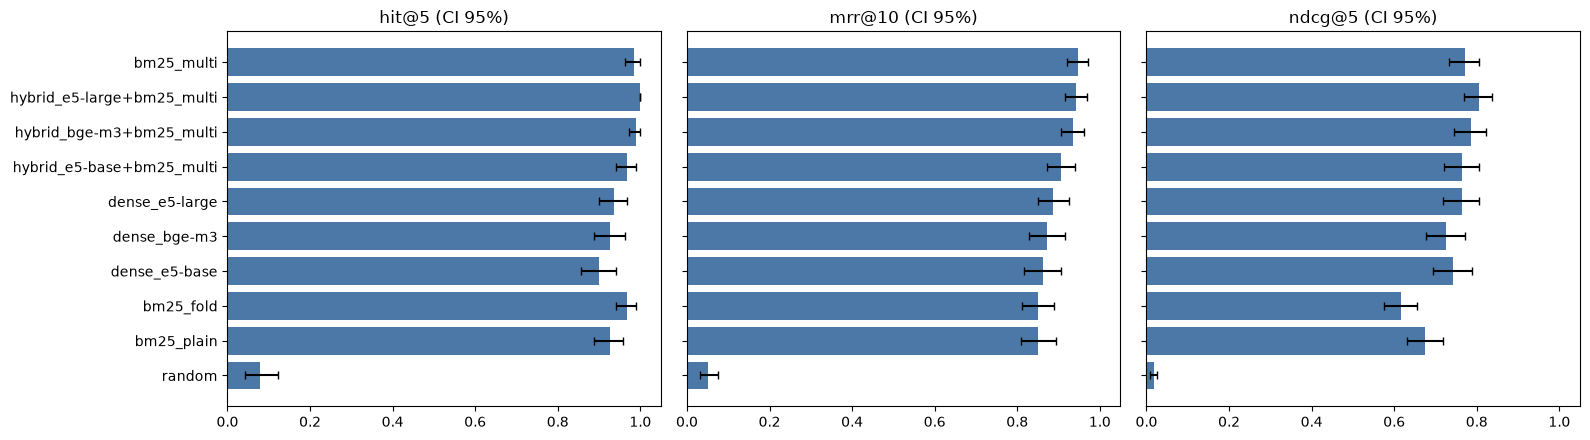

In [6]:
ev = ret_df[ret_df["evaluable"]]
order = summary["retriever"].tolist()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, metric in zip(axes, ["hit@5", "mrr@10", "ndcg@5"]):
    stats = [bootstrap_ci(ev[ev.retriever == r][metric].tolist()) for r in order]
    means = [s[0] for s in stats]
    err = [[m - s[1] for m, s in zip(means, stats)], [s[2] - m for m, s in zip(means, stats)]]
    ax.barh(order, means, xerr=err, capsize=3, color="#4C78A8")
    ax.set_title(f"{metric} (CI 95%)"); ax.set_xlim(0, 1.05)
axes[0].invert_yaxis()
plt.tight_layout(); plt.show()

### Theo loại câu hỏi

In [7]:
print("Hit@5"); display(bm.by_type(ret_df, "hit@5").loc[order])
print("MRR@10"); display(bm.by_type(ret_df, "mrr@10").loc[order])

Hit@5


type,descriptive,fact,multi,no_diacritics,paraphrase
retriever,,,,,
bm25_multi,1.000,0.992,1.000,1.000,0.926
hybrid_e5-large+bm25_multi,1.000,1.000,1.000,1.000,1.000
hybrid_bge-m3+bm25_multi,1.000,1.000,0.923,0.947,1.000
hybrid_e5-base+bm25_multi,1.000,1.000,1.000,0.737,0.963
dense_e5-large,1.000,1.000,1.000,0.421,0.963
dense_bge-m3,1.000,1.000,0.923,0.368,0.963
dense_e5-base,1.000,0.992,0.923,0.211,0.926
bm25_fold,0.875,0.967,1.000,0.947,1.000
bm25_plain,0.875,1.000,1.000,0.368,0.963


MRR@10


type,descriptive,fact,multi,no_diacritics,paraphrase
retriever,,,,,
bm25_multi,0.844,0.961,0.923,1.000,0.894
hybrid_e5-large+bm25_multi,1.000,0.978,0.949,0.754,0.901
hybrid_bge-m3+bm25_multi,0.917,0.979,0.846,0.723,0.929
hybrid_e5-base+bm25_multi,0.938,0.974,0.949,0.514,0.849
dense_e5-large,1.000,0.967,0.897,0.362,0.862
dense_bge-m3,1.000,0.971,0.667,0.240,0.933
dense_e5-base,1.000,0.960,0.897,0.156,0.859
bm25_fold,0.598,0.852,0.962,0.884,0.846
bm25_plain,0.797,0.938,0.962,0.237,0.855


### Câu nhiều địa danh (`multi`): Recall@k mức địa danh

,place_recall@1,place_recall@3,place_recall@5,place_recall@10
retriever,,,,
bm25_multi,0.281,0.557,0.701,0.879
hybrid_e5-large+bm25_multi,0.307,0.627,0.793,0.908
hybrid_bge-m3+bm25_multi,0.262,0.505,0.613,0.763
hybrid_e5-base+bm25_multi,0.307,0.614,0.806,0.904
dense_e5-large,0.292,0.586,0.774,0.856
dense_bge-m3,0.199,0.490,0.550,0.700
dense_e5-base,0.269,0.492,0.697,0.876
bm25_fold,0.307,0.621,0.754,0.851
bm25_plain,0.307,0.675,0.822,0.914


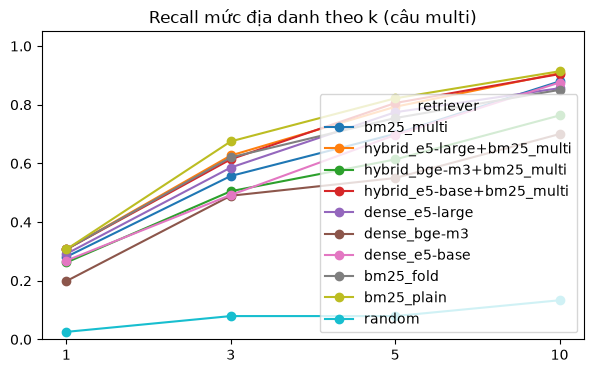

In [8]:
multi = ev[ev.type == "multi"]
if len(multi):
    curve = multi.groupby("retriever")[[f"place_recall@{k}" for k in bm.K_VALUES]].mean().loc[order]
    display(curve)
    ax = curve.T.plot(marker="o", figsize=(7, 4), title="Recall mức địa danh theo k (câu multi)")
    ax.set_xticks(range(len(bm.K_VALUES)), [str(k) for k in bm.K_VALUES]); ax.set_ylim(0, 1.05); plt.show()
else:
    print("Không có câu multi.")

## 4. Độ trễ truy hồi

,p50_ms,p95_ms,max
retriever,,,
bm25_multi,3.480,6.317,9.008
hybrid_e5-large+bm25_multi,19.030,22.398,30.258
hybrid_bge-m3+bm25_multi,18.953,22.270,27.771
hybrid_e5-base+bm25_multi,12.593,15.061,16.845
dense_e5-large,13.865,15.402,17.197
dense_bge-m3,14.669,16.045,19.159
dense_e5-base,8.438,10.105,12.459
bm25_fold,1.366,2.100,2.414
bm25_plain,1.185,1.895,2.630


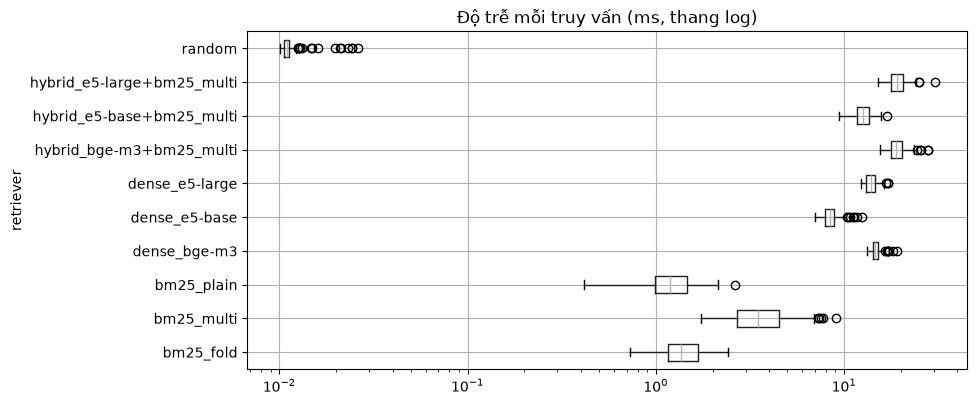

In [9]:
lat = ev.groupby("retriever")["latency_ms"].describe(percentiles=[.5, .95])[["50%", "95%", "max"]].loc[order]
display(lat.rename(columns={"50%": "p50_ms", "95%": "p95_ms"}))
ax = ev.boxplot(column="latency_ms", by="retriever", vert=False, figsize=(9, 4.5))
ax.set_xscale("log"); ax.set_title("Độ trễ mỗi truy vấn (ms, thang log)"); plt.suptitle(""); plt.show()

## 5. So sánh cặp (bootstrap, cùng câu hỏi)

In [10]:
best = next(r for r in order if r != "random")
rows = []
for other in order:
    if other == best:
        continue
    for metric in ["hit@5", "mrr@10", "ndcg@5"]:
        mean, lo, hi = bm.compare(ret_df, best, other, metric)
        rows.append({"so sánh": f"{best} − {other}", "chỉ số": metric, "chênh lệch": mean,
                     "CI 95%": f"[{lo:+.3f}, {hi:+.3f}]", "có ý nghĩa": not (lo <= 0 <= hi)})
cmp_df = pd.DataFrame(rows)
cmp_df.to_csv(OUT / "retrieval_paired.csv", index=False)
print("Retriever tốt nhất theo MRR:", best)
display(cmp_df)

Retriever tốt nhất theo MRR: bm25_multi


,so sánh,chỉ số,chênh lệch,CI 95%,có ý nghĩa
0,bm25_multi − hybrid_e5-large+bm25_multi,hit@5,-0.016,"[-0.037, +0.000]",False
1,bm25_multi − hybrid_e5-large+bm25_multi,mrr@10,0.004,"[-0.027, +0.035]",False
2,bm25_multi − hybrid_e5-large+bm25_multi,ndcg@5,-0.033,"[-0.062, -0.005]",True
3,bm25_multi − hybrid_bge-m3+bm25_multi,hit@5,-0.005,"[-0.027, +0.016]",False
4,bm25_multi − hybrid_bge-m3+bm25_multi,mrr@10,0.013,"[-0.017, +0.043]",False
5,bm25_multi − hybrid_bge-m3+bm25_multi,ndcg@5,-0.013,"[-0.042, +0.015]",False
6,bm25_multi − hybrid_e5-base+bm25_multi,hit@5,0.016,"[-0.016, +0.048]",False
7,bm25_multi − hybrid_e5-base+bm25_multi,mrr@10,0.041,"[+0.005, +0.079]",True
8,bm25_multi − hybrid_e5-base+bm25_multi,ndcg@5,0.008,"[-0.027, +0.042]",False
9,bm25_multi − dense_e5-large,hit@5,0.048,"[+0.005, +0.090]",True


## 6. Phân tích lỗi của retriever tốt nhất

In [11]:
qmap = {q.id: q for q in queries}
fails = ev[(ev.retriever == best) & ((ev["hit@5"] == 0) | (ev["mrr@10"] < 0.5))].copy()
fails["query"] = fails["id"].map(lambda i: qmap[i].query)
fails["expected"] = fails["id"].map(lambda i: ", ".join(sorted(qmap[i].relevant)))
print(f"{len(fails)} câu trượt top-5 hoặc chunk đúng đầu tiên ở hạng > 2")
display(fails[["id", "type", "query", "expected", "hit@5", "mrr@10", "top_chunks"]])

6 câu trượt top-5 hoặc chunk đúng đầu tiên ở hạng > 2


,id,type,query,expected,hit@5,mrr@10,top_chunks
378,q004,fact,Lăng vua Tự Đức còn có tên gọi khác là gì?,wikidata:Q7481171,0.000,0.143,Sông Hương#37327-3 | Lăng Thiệu Trị#217457-2 | Lăng Thiệu Trị#217457-4
392,q018,paraphrase,"Cây cầu sắt bắc qua sông Hương xây thời Pháp thuộc, có sáu nhịp",wikidata:Q10752407,0.000,0.143,Cầu Dã Viên#1522126-3 | Cầu Chợ Dinh#19513867-0 | Cầu Dã Viên#1522126-0
400,q026,paraphrase,Tòa thành bao quanh Hoàng thành Huế xây theo kiểu Vauban,wikidata:Q877185,0.000,0.000,Hoàng thành Huế#230007-2 | Hoàng thành Huế#230007-4 | Điện Thái Hòa (Hoàng thành Huế)#201789-7
402,q028,descriptive,Sông Hương bắt nguồn từ đâu?,wikidata:Q1515971,1.000,0.250,Sông Bồ#113139-2 | Sông Hữu Trạch#305662-1 | Sông Bồ#113139-0
465,q091,fact,Hoàng thành Huế có mấy cửa ra vào?,wikidata:Q10769129,1.000,0.250,Thái Tổ miếu (Hoàng thành Huế)#202232-2 | Ngọ Môn (Hoàng thành Huế)#201788-12 | Ngọ Môn (Hoàng thành Huế)#201788-1
479,q105,fact,Lăng Gia Long được xây từ năm nào đến năm nào?,wikidata:Q7818615,1.000,0.333,Cố đô Huế#52289-21 | Văn miếu (Huế)#230180-1 | Lăng Gia Long#216866-1


## 7. Sinh câu trả lời (TTFT, tokens/giây)

Dùng retriever hệ thống đã chốt (`GEN_RETRIEVER`), top-5 chunk làm ngữ cảnh. Mỗi model được gọi một lần "khởi động" trước khi đo
(`cold_start_s` = thời gian nạp model). Embedder chuyển về CPU (`GEN_EMBED_DEVICE`) để LLM có trọn VRAM; thời gian truy hồi vì thế tăng nhẹ và được tính
vào TTFT đầu-cuối. Model 9B (6.4 GB + context 8192) vẫn không vừa trọn 8 GB VRAM, Ollama đẩy ~12% sang CPU.

In [12]:
if RUN_GENERATION:
    print('Retriever tốt nhất theo MRR:', best, '| retriever hệ thống dùng để sinh:', GEN_RETRIEVER)
    gen_retriever = retrievers[GEN_RETRIEVER]
    retrievers = {GEN_RETRIEVER: gen_retriever}
    gen_retriever.dense.embedder.to(GEN_EMBED_DEVICE)
    bm.free_gpu_cache()
    gen_df, cold = bm.run_generation(gen_retriever, chunks, queries, LLM_MODELS)
    gen_df.to_csv(OUT / "generation_per_query.csv", index=False)
    gen_summary = bm.summarize_generation(gen_df, cold)
    gen_summary.to_csv(OUT / "generation_summary.csv", index=False)
    display(gen_summary.T)
else:
    print("Bỏ qua (RUN_GENERATION=False).")

Retriever tốt nhất theo MRR: bm25_multi | retriever hệ thống dùng để sinh: hybrid_bge-m3+bm25_multi


,0,1
model,qwen3.5:4b,qwen3.5:9b
n,188,188
ttft_ms_p50,3193.779,4673.337
ttft_ms_p95,4025.046,8278.943
e2e_ttft_ms_p50,3251.451,4726.587
e2e_ttft_ms_p95,4086.273,8338.192
total_ms_p50,4069.620,7802.795
total_ms_p95,6937.940,17633.340
e2e_total_ms_p50,4130.062,7865.624
e2e_total_ms_p95,7006.160,17703.265


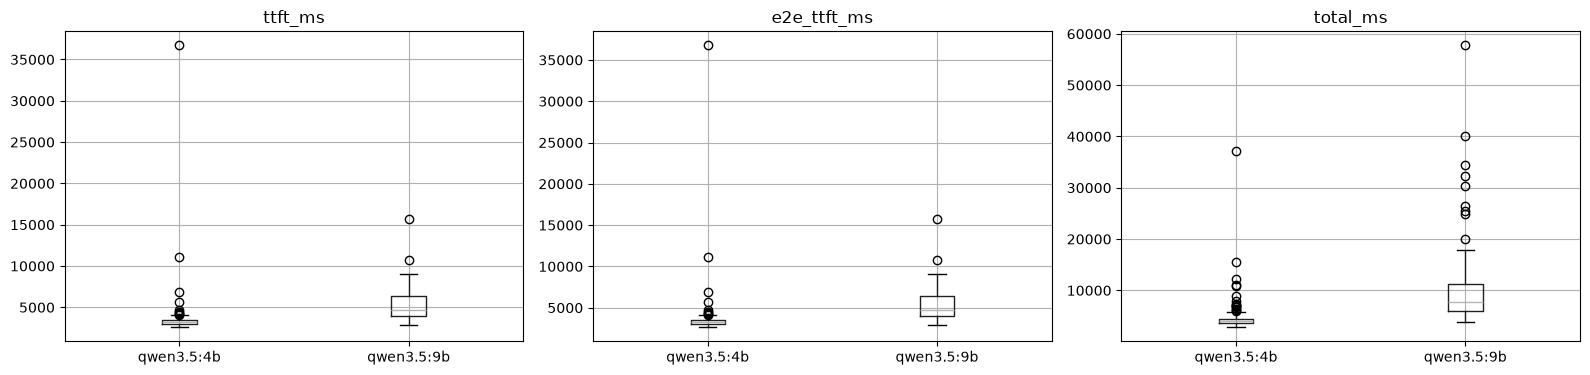

model                qwen3.5:4b  qwen3.5:9b
tokens_per_s  count     188.000     188.000
              mean       40.990      12.802
              std        55.630      11.722
              min        13.705       2.849
              25%        31.604       6.707
              50%        35.062       9.667
              75%        40.368      13.773
              max       789.373     117.358
output_tokens count     188.000     188.000
              mean       37.309      38.117
              std        47.164      48.669
              min         8.000       8.000
              25%        17.000      17.750
              50%        25.000      25.000
              75%        35.000      33.000
              max       352.000     349.000

In [13]:
if RUN_GENERATION:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, col in zip(axes, ["ttft_ms", "e2e_ttft_ms", "total_ms"]):
        gen_df.boxplot(column=col, by="model", ax=ax); ax.set_title(col); ax.set_xlabel("")
    plt.suptitle(""); plt.tight_layout(); plt.show()
    display(gen_df.groupby("model")[["tokens_per_s", "output_tokens"]].describe().T)

In [14]:
if RUN_GENERATION:
    kw = gen_df.dropna(subset=["keyword_recall"])
    print("Độ phủ từ khoá đáp án theo model, tách theo việc ngữ cảnh có chunk đúng hay không:")
    display(kw.pivot_table(index="model", columns="context_has_answer", values="keyword_recall", aggfunc=["mean", "size"]))
    sample = gen_df[gen_df.model == LLM_MODELS[0]].head(10).copy()
    sample["query"] = sample["id"].map(lambda i: qmap[i].query)
    display(sample[["id", "query", "answer", "keyword_recall", "cited", "refused", "ttft_ms"]])

Độ phủ từ khoá đáp án theo model, tách theo việc ngữ cảnh có chunk đúng hay không:


mean        size      
context_has_answer False True  False True 
model                                     
qwen3.5:4b         0.000 0.908     1   142
qwen3.5:9b         0.000 0.951     1   142

,id,query,answer,keyword_recall,cited,refused,ttft_ms
0,q001,Chùa Thiên Mụ được xây dựng vào năm nào?,Chùa Thiên Mụ chính thức khởi lập năm Tân Sửu (1601) [4].,1.000,True,False,2864.109
1,q002,Tháp Phước Duyên ở chùa Thiên Mụ có mấy tầng?,Tháp Phước Duyên có 7 tầng [1].,1.000,True,False,3017.415
2,q004,Lăng vua Tự Đức còn có tên gọi khác là gì?,Lăng vua Tự Đức còn có tên gọi là Khiêm Cung và Khiêm Lăng [3].,1.000,True,False,3028.250
3,q005,"Lăng của vị vua làm nhiều thơ, có hồ Lưu Khiêm và Xung Khiêm tạ",Lăng của vị vua đó là Lăng Tự Đức [1].,NaN,True,False,2993.989
4,q006,Lăng Khải Định còn gọi là gì?,Lăng Khải Định còn gọi là Ứng Lăng [1].,1.000,True,False,2908.690
5,q007,"Lăng vua nào được trang trí bằng mảnh sành sứ ghép, pha kiến trúc phương Tây",Lăng Khải Định là lăng vua được trang trí bằng mảnh sành sứ ghép và pha trộn kiến trúc phương Đông với phương Tây [1...,NaN,True,False,2950.236
6,q008,Tên chính thức của lăng vua Minh Mạng,"Tên chính thức của lăng vua Minh Mạng là **Hiếu Lăng** (hay còn gọi là Lăng Minh Mệnh) [1], [2].",1.000,True,False,2917.966
7,q009,Lăng Gia Long có tên gọi là gì?,Lăng Gia Long còn được gọi là Thiên Thọ Lăng [1].,1.000,True,False,2755.538
8,q010,Lăng Thiệu Trị còn được gọi là gì?,Lăng Thiệu Trị còn được gọi là Xương Lăng [1].,1.000,True,False,2932.435
9,q011,Lăng Đồng Khánh có tên chữ là gì?,Tư liệu hiện có không đề cập.,0.000,False,True,2988.657
